# 01 · PCA Report — Employee Workforce Segmentation
Reduce the HR feature space, justify the number of components, and visualise employee groups.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
df = pd.read_csv("../data/employees.csv")
df.head()

,employee_id,department,age,tenure_years,monthly_salary,performance_rating,engagement_score,overtime_hours_month,absenteeism_days,training_hours,years_since_promotion,manager_rating,projects_handled,commute_km,left_company
0,E1000,HR,32,3.6,6010.0,3.3,2.8,5,7,0,3.6,1.9,2,6,1
1,E1001,Customer Support,43,11.5,6250.0,3.0,8.0,4,5,26,1.0,3.7,4,24,0
2,E1002,Sales,52,11.0,3970.0,2.8,5.1,14,7,2,8.0,1.9,1,19,1
3,E1003,Engineering,33,3.4,4550.0,3.4,3.5,60,11,21,3.3,2.9,7,1,1
4,E1004,Operations,27,0.3,6420.0,5.0,8.2,26,3,57,0.3,4.6,7,10,0


## 1. Feature selection
We cluster on **behavioural and HR attributes only**. `employee_id`, `department` (categorical, analysed afterwards) and `left_company` (historical outcome, kept for *validation*) are excluded so no label leaks into the unsupervised model.

In [2]:
FEATURES = [c for c in df.columns if c not in ("employee_id", "department", "left_company")]
print(len(FEATURES), "features:", FEATURES)
df[FEATURES].describe().T.round(2)

12 features: ['age', 'tenure_years', 'monthly_salary', 'performance_rating', 'engagement_score', 'overtime_hours_month', 'absenteeism_days', 'training_hours', 'years_since_promotion', 'manager_rating', 'projects_handled', 'commute_km']


,count,mean,std,min,25%,50%,75%,max
age,1200.0,37.03,8.41,21.0,31.0,37.0,43.0,62.0
tenure_years,1200.0,6.82,4.36,0.1,3.4,6.6,9.8,22.0
monthly_salary,1200.0,5559.18,1724.73,2080.0,4227.5,5400.0,6620.0,11380.0
performance_rating,1200.0,3.51,0.80,1.1,3.0,3.5,4.1,5.0
engagement_score,1200.0,6.10,2.08,1.0,4.4,6.7,7.7,10.0
overtime_hours_month,1200.0,15.80,13.81,0.0,6.0,11.0,20.0,66.0
absenteeism_days,1200.0,5.81,4.32,0.0,2.0,5.0,9.0,22.0
training_hours,1200.0,26.78,17.01,0.0,13.0,25.0,39.0,79.0
years_since_promotion,1200.0,2.75,1.94,0.0,1.1,2.5,4.1,9.1
manager_rating,1200.0,3.60,0.86,1.0,3.1,3.8,4.2,5.0


## 2. Scaling (mandatory)
PCA maximises variance, so a feature measured in thousands (salary) would swamp one measured on a 1–5 scale. `StandardScaler` gives every feature mean 0 and unit variance.

In [3]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("means ≈", X.mean(0).round(6).max(), "| stds ≈", X.std(0).round(6).min())

means ≈ 0.0 | stds ≈ 1.0


## 3. Scree plot and explained variance

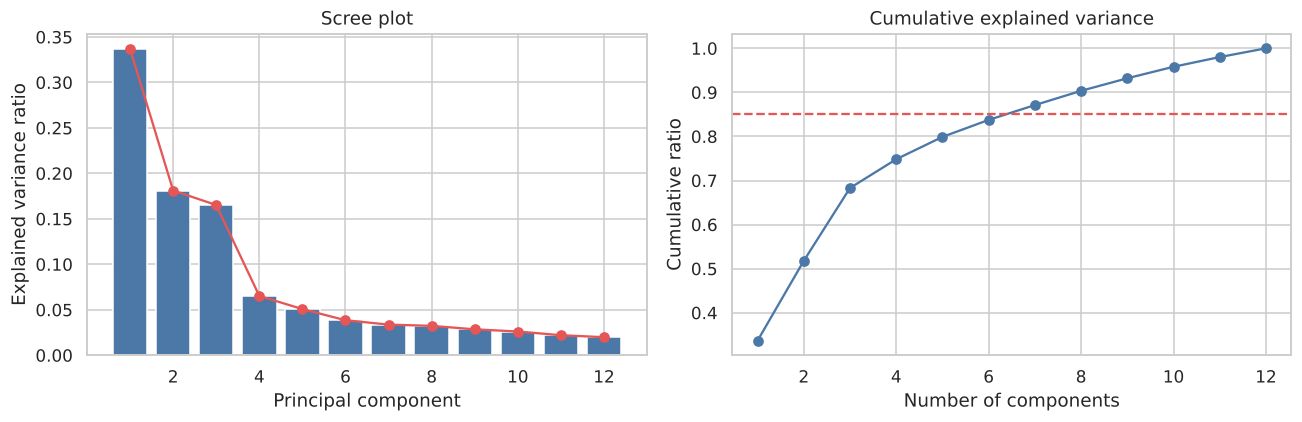

,PC,variance,cumulative
0,PC1,0.337,0.337
1,PC2,0.181,0.518
2,PC3,0.165,0.683
3,PC4,0.065,0.748
4,PC5,0.051,0.799
5,PC6,0.038,0.838
6,PC7,0.034,0.871
7,PC8,0.032,0.904
8,PC9,0.029,0.932


In [4]:
pca_full = PCA().fit(X)
evr = pca_full.explained_variance_ratio_; cum = evr.cumsum()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(evr)+1), evr, color="#4C78A8"); ax[0].plot(range(1, len(evr)+1), evr, "o-", color="#E45756")
ax[0].set(title="Scree plot", xlabel="Principal component", ylabel="Explained variance ratio")
ax[1].plot(range(1, len(cum)+1), cum, "o-", color="#4C78A8")
ax[1].axhline(0.85, ls="--", color="#E45756"); ax[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative ratio")
plt.tight_layout(); plt.savefig("../reports/fig_scree.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))], "variance": evr.round(3), "cumulative": cum.round(3)}).head(9)

## 4. Choosing the number of components
We keep the smallest number of components that explains **≥ 85 %** of the variance (inside the 80–90 % guideline).

In [5]:
n_comp = int(np.argmax(cum >= 0.85) + 1)
print(f"Components kept: {n_comp}  -> {cum[n_comp-1]:.1%} of variance retained ({len(FEATURES)} -> {n_comp} dimensions)")
pca = PCA(n_components=n_comp, random_state=42)
Z = pca.fit_transform(X)
pd.DataFrame(Z, columns=[f"PC{i+1}" for i in range(n_comp)]).assign(employee_id=df.employee_id).to_csv("../data/employees_pca.csv", index=False)

Components kept: 7  -> 87.1% of variance retained (12 -> 7 dimensions)


## 5. What do the components mean? (loadings)

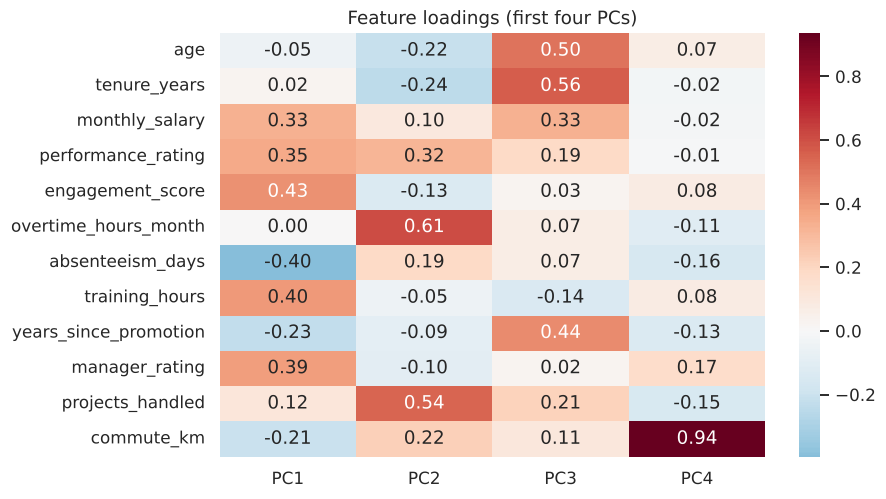

PC1 driven by: engagement_score (+0.43), training_hours (+0.40), absenteeism_days (-0.40), manager_rating (+0.39)
PC2 driven by: overtime_hours_month (+0.61), projects_handled (+0.54), performance_rating (+0.32), tenure_years (-0.24)
PC3 driven by: tenure_years (+0.56), age (+0.50), years_since_promotion (+0.44), monthly_salary (+0.33)


In [6]:
load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=[f"PC{i+1}" for i in range(n_comp)])
plt.figure(figsize=(8, 5)); sns.heatmap(load.iloc[:, :4], annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Feature loadings (first four PCs)"); plt.savefig("../reports/fig_loadings.png", bbox_inches="tight"); plt.show()
for pc in ["PC1", "PC2", "PC3"]:
    top = load[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, "driven by:", ", ".join(f"{t} ({load.loc[t, pc]:+.2f})" for t in top))
load.round(3).to_csv("../reports/pca_loadings.csv")

## 6. 2-D view of the workforce (before clustering)

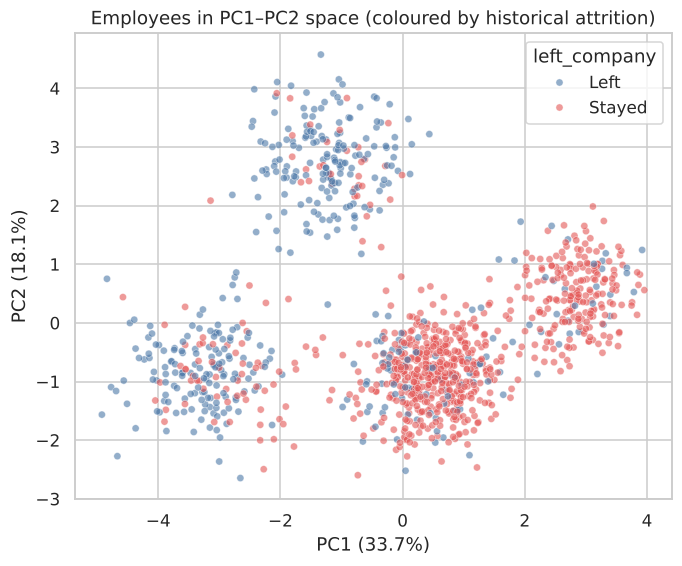

In [7]:
plt.figure(figsize=(7, 5.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df.left_company.map({0: "Stayed", 1: "Left"}), alpha=.6, s=22, palette=["#4C78A8", "#E45756"])
plt.xlabel(f"PC1 ({evr[0]:.1%})"); plt.ylabel(f"PC2 ({evr[1]:.1%})"); plt.title("Employees in PC1–PC2 space (coloured by historical attrition)")
plt.savefig("../reports/fig_pca_attrition.png", bbox_inches="tight"); plt.show()

**Take-aways** — a handful of components capture most of the signal; PC1 contrasts engaged/high-performing/well-trained staff with disengaged/absent staff, and PC2 captures workload (overtime, projects, commute). Attrition concentrates at one end of PC1 even though the model never saw it.